# Zimbabwe Healthcare Accessibility Explorer
## Notebook 1 — Project Overview and Data Inspection
**Author: Tinashe Clifford Makandise**

### Research question
Which populated areas in Zimbabwe are relatively far from mapped public-sector healthcare facilities?

This first notebook inspects source files and records quality issues. It does not calculate access indicators or make service-placement recommendations. Later notebooks will prepare spatial data, explore patterns, calculate population-weighted nearest-facility distances, validate results and build a Streamlit app.

### Run this notebook
Extract the starter ZIP first. Keep this file inside the project's `notebooks/` folder. Install `requirements-dev.txt` in your Python environment, open this notebook in Jupyter, then select **Run All**. The supplied facility workbook and population GeoTIFF allow this notebook to run offline after dependencies are installed.

### Scope
The facility source is Maina et al. (2019), a historical compilation assembled across countries during 2012–2018. It includes government, local-authority and some not-for-profit providers; it does not cover every healthcare provider or demonstrate current operational status. Population estimates refer to 2020. Their combination supports an exploratory mixed-reference-period analysis, not an exact assessment of present-day access.

### 1. Sources and study design
- Facilities: [Figshare record](https://doi.org/10.6084/m9.figshare.7725374), original Excel workbook. [Maina et al. study](https://doi.org/10.1038/s41597-019-0142-2).
- Population: [WorldPop Zimbabwe 2020, approximately 1 km](https://hub.worldpop.org/geodata/summary?id=38911). Values are estimated **people per cell**, not population density. The country total is adjusted to a UN population estimate.
- Boundaries: [OCHA/HDX Zimbabwe COD-AB](https://data.humdata.org/dataset/cod-ab-zwe). Catalogue metadata and user-supplied GeoJSON layers are included. Inspect their geometry and codes below; preserve original file bytes and source metadata.

The data will measure geographic proximity. Distance does not establish travel time, affordability, staffing, capacity or quality. Population cells will be represented by points in the later distance analysis, introducing within-cell approximation. District boundaries are reporting units, not barriers to access; a nearest facility may lie in a neighbouring district.

In [1]:
from pathlib import Path
import json, hashlib, platform, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import openpyxl

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, REPORTS = ROOT / "data/raw", ROOT / "reports"
MAPS, TABLES = ROOT / "outputs/maps", ROOT / "outputs/tables"
for folder in [REPORTS, MAPS, TABLES]:
    folder.mkdir(parents=True, exist_ok=True)
FACILITY_PATH = RAW / "ssa_public_health_facilities_2019.xlsx"
POPULATION_PATH = RAW / "zwe_ppp_2020_1km_Aggregated_UNadj.tif"
for path in [FACILITY_PATH, POPULATION_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing supplied source file: {path}. Extract the full starter ZIP.")
versions = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
            "rasterio": rasterio.__version__, "openpyxl": openpyxl.__version__}
print("Environment:", versions)
inventory = pd.read_csv(REPORTS / "source_inventory.csv")
print(inventory[["dataset", "reference_period", "status"]].to_string(index=False))

Environment: {'python': '3.12.14', 'pandas': '2.2.3', 'numpy': '2.3.5', 'rasterio': '1.5.2', 'openpyxl': '3.1.5'}
                  dataset                                                                                       reference_period                                                                                                                status
    Healthcare facilities Historical compilation assembled 2012–2018; published 2019; individual country source years may differ                                                                          downloaded; original repository MD5 verified
        Population counts                                                                  2020 modelled population, UN-adjusted                                                                                                            downloaded
Administrative boundaries                          Catalogue: source created 2018, reviewed January 2025; verify downloaded file user-supplied ex

### 2. Preserve and fingerprint the original files
The workbook was downloaded from the original Figshare file endpoint. Verify its published MD5, then record SHA-256 fingerprints for reproducibility. Hashes detect changed bytes; they do not prove the correctness of the underlying records.

Raw files are never overwritten by this notebook. The source inventory stores the original download addresses. Download date is not observation date.

In [2]:
assert hashlib.md5(FACILITY_PATH.read_bytes()).hexdigest() == "3bf56fc31081c8fd798789a3d70564b8", "Workbook differs from the inspected Figshare version."
fingerprints = {}
for path in [FACILITY_PATH, POPULATION_PATH]:
    fingerprints[path.name] = {"bytes": path.stat().st_size,
                               "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
print(pd.DataFrame(fingerprints).T.to_string())

                                          bytes                                                            sha256
ssa_public_health_facilities_2019.xlsx  5495174  6ab31b0d2601e0cd53e6360c5f6f9b415b2f6e2895b7a687b35f2ddedc3950b1
zwe_ppp_2020_1km_Aggregated_UNadj.tif   2127638  5152f3fcefdcd5986f7ef844d19a31f1489c7da01ed9169b8e00958a40d32866


### 3. Inspect the workbook and extract Zimbabwe records
Inspect the worksheet names and original fields. The `Abbreviations` worksheet helps interpret ownership and location-source terms. Preserve the original columns and use a source row identifier for traceability. This is a country subset, not a cleaned analytical dataset.

In [3]:
workbook = pd.ExcelFile(FACILITY_PATH)
print("Worksheets:", workbook.sheet_names)
all_facilities = pd.read_excel(workbook, sheet_name="SSA MFL")
required = {"Country", "Admin1", "Facility name", "Facility type", "Ownership", "Lat", "Long", "LL source"}
assert required.issubset(all_facilities.columns)
country_mask = all_facilities["Country"].astype(str).str.strip().str.casefold().eq("zimbabwe")
zim = all_facilities.loc[country_mask].copy()
zim.insert(0, "source_excel_row", zim.index + 2)
assert len(zim) > 0
print("Full database rows:", len(all_facilities))
print("Zimbabwe rows:", len(zim))
print("Columns:", list(zim.columns))
print(zim.head(5).to_string(index=False))
print("Missing values:")
print(zim.isna().sum().to_string())

Worksheets: ['SSA MFL', 'Abbreviations']
Full database rows: 98745
Zimbabwe rows: 1236
Columns: ['source_excel_row', 'Country', 'Admin1', 'Facility name', 'Facility type', 'Ownership', 'Lat', 'Long', 'LL source']
 source_excel_row  Country   Admin1       Facility name Facility type       Ownership      Lat      Long    LL source
            97510 Zimbabwe Bulawayo      Central Clinic        Clinic Local authority -20.1664 28.616900     Geonames
            97511 Zimbabwe Bulawayo Cowdray Park Clinic        Clinic Local authority -20.0816 28.515591 Google Earth
            97512 Zimbabwe Bulawayo  Dr. Shennan Clinic        Clinic Local authority      NaN       NaN          NaN
            97513 Zimbabwe Bulawayo E. F. watson Clinic        Clinic Local authority      NaN       NaN          NaN
            97514 Zimbabwe Bulawayo   Emakandeni Clinic        Clinic Local authority -20.1139 28.527800     Geonames
Missing values:
source_excel_row     0
Country              0
Admin1           

### 4. Audit coordinates and potential duplicate records
Coerce coordinates for inspection without changing raw values. Global-range checks are basic validity checks; a broad Zimbabwe screening box is deliberately approximate and does not replace a point-in-polygon country-boundary test.

Missing coordinates remain in the review extract. Do not replace them with district centroids and treat those as verified facility locations. Exact duplicate rows and shared coordinates require investigation: separate services can share a site, and rounded coordinates may coincide.

In [4]:
lat = pd.to_numeric(zim["Lat"], errors="coerce")
lon = pd.to_numeric(zim["Long"], errors="coerce")
finite = pd.Series(np.isfinite(lat) & np.isfinite(lon), index=zim.index)
usable_global = finite & lat.between(-90, 90) & lon.between(-180, 180)
missing_pair = lat.isna() | lon.isna()
broad_screen = lat.between(-23, -15) & lon.between(25, 34)
exact_duplicate_rows = int(zim.duplicated(subset=list(required)).sum())
shared_coordinates = int(pd.DataFrame({"lat": lat[usable_global], "lon": lon[usable_global]}).duplicated(keep=False).sum())
coordinate_audit = {
    "zimbabwe_records": len(zim), "usable_global_coordinate_pairs": int(usable_global.sum()),
    "missing_either_coordinate": int(missing_pair.sum()),
    "nonmissing_invalid_global_coordinates": int((~missing_pair & ~usable_global).sum()),
    "outside_broad_screen_with_usable_coordinates": int((usable_global & ~broad_screen).sum()),
    "exact_duplicate_rows": exact_duplicate_rows,
    "rows_sharing_coordinate_pair": shared_coordinates,
}
print(json.dumps(coordinate_audit, indent=2))
print("Coordinate summary:")
print(pd.DataFrame({"latitude": lat, "longitude": lon}).describe().round(5).to_string())
print("Boundary containment and duplicates will be reviewed in Notebook 2.")

{
  "zimbabwe_records": 1236,
  "usable_global_coordinate_pairs": 1201,
  "missing_either_coordinate": 35,
  "nonmissing_invalid_global_coordinates": 0,
  "outside_broad_screen_with_usable_coordinates": 0,
  "exact_duplicate_rows": 0,
  "rows_sharing_coordinate_pair": 0
}
Coordinate summary:
         latitude   longitude
count  1201.00000  1201.00000
mean    -18.84284    30.63908
std       1.42588     1.51418
min     -22.31725    25.82583
25%     -20.03928    29.60347
50%     -18.74136    30.92250
75%     -17.71670    31.81130
max     -15.70058    33.00286
Boundary containment and duplicates will be reviewed in Notebook 2.


### 5. Summarise facility categories and ownership
Count records by source category and province label. These counts are descriptive inventory measures. They do not measure the number of beds, staff, operational facilities today or the population actually served. `Admin1` labels will be compared with boundary names later rather than silently assumed to match.

Facility types:
 Facility type
Clinic                          563
Rural Health Clinic             504
Rural Hospital                  108
District Hospital                47
Provincial Hospital               7
Central Hospital                  6
District/Provincial Hospital      1
Ownership:
 Ownership
Local authority    657
MoH                471
FBO                107
NGO                  1
Source province labels:
 Admin1
Manicaland             223
Midlands               173
Mashonaland East       168
Masvingo               151
Mashonaland West       136
Mashonaland Central    123
Matabeleland South     102
Matabeleland North      87
Harare                  27
Bulawayo                22
Matabeleland South      10
Matabeleland North       6
Mashonaland West         5
Mashonaland East         3


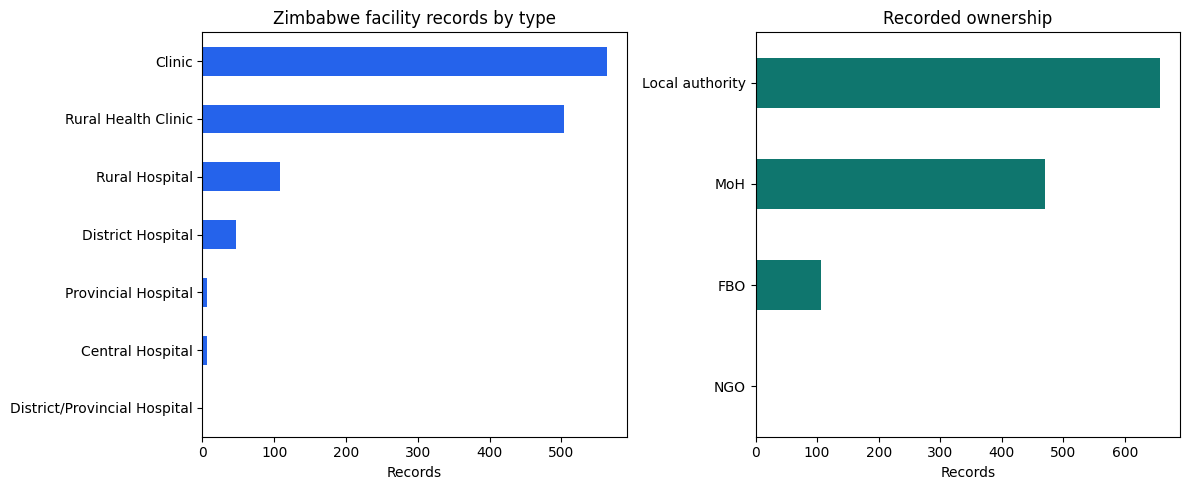

In [5]:
types = zim["Facility type"].fillna("Missing").value_counts()
ownership = zim["Ownership"].fillna("Missing").value_counts()
province_counts = zim["Admin1"].fillna("Missing").value_counts()
print("Facility types:\n", types.to_string())
print("Ownership:\n", ownership.to_string())
print("Source province labels:\n", province_counts.to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
types.sort_values().plot.barh(ax=axes[0], color="#2563eb")
ownership.sort_values().plot.barh(ax=axes[1], color="#0f766e")
axes[0].set(title="Zimbabwe facility records by type", xlabel="Records", ylabel="")
axes[1].set(title="Recorded ownership", xlabel="Records", ylabel="")
plt.tight_layout()
plt.savefig(MAPS / "01_facility_categories.png", dpi=150, bbox_inches="tight")
plt.show()

### 6. Inspect the population raster
Read the native CRS, dimensions, cell spacing, NoData definition and valid-cell totals. The nominal “1 km” grid is actually 30 arc-seconds in a geographic CRS; physical dimensions vary with latitude. Do not calculate area or distances from degrees as if they were metres.

The reported sum is the supplied raster's total before any district clipping or assignment. It will be the starting reference for later population reconciliation. NoData and zero population have different meanings.

In [6]:
with rasterio.open(POPULATION_PATH) as src:
    population = src.read(1, masked=True)
    raster_info = {"crs": str(src.crs), "width": src.width, "height": src.height,
                   "resolution_degrees": list(src.res), "bounds": list(src.bounds),
                   "nodata": src.nodata, "valid_cells": int(population.count()),
                   "masked_cells": int(np.ma.getmaskarray(population).sum()),
                   "positive_cells": int((population.filled(0) > 0).sum()),
                   "negative_valid_cells": int((population.compressed() < 0).sum()),
                   "population_sum_before_clipping": float(population.sum(dtype=np.float64))}
    raster_extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
assert raster_info["negative_valid_cells"] == 0
assert np.isfinite(population.compressed()).all()
print(json.dumps(raster_info, indent=2))

{
  "crs": "EPSG:4326",
  "width": 938,
  "height": 817,
  "resolution_degrees": [
    0.0083333333,
    0.0083333333
  ],
  "bounds": [
    25.240416568504628,
    -22.408749692472906,
    33.057083203904625,
    -15.600416386372906
  ],
  "nodata": -99999.0,
  "valid_cells": 479646,
  "masked_cells": 286700,
  "positive_cells": 479646,
  "negative_valid_cells": 0,
  "population_sum_before_clipping": 14862927.0006076
}


### 7. Create an initial coordinate map
Display the modelled population surface and usable facility coordinate pairs together. Log transformation is for colour display only; original population counts are preserved. The scatter plot is not a distance analysis, and no basemap or district boundary is fabricated. Potential duplicate points have not yet been resolved.

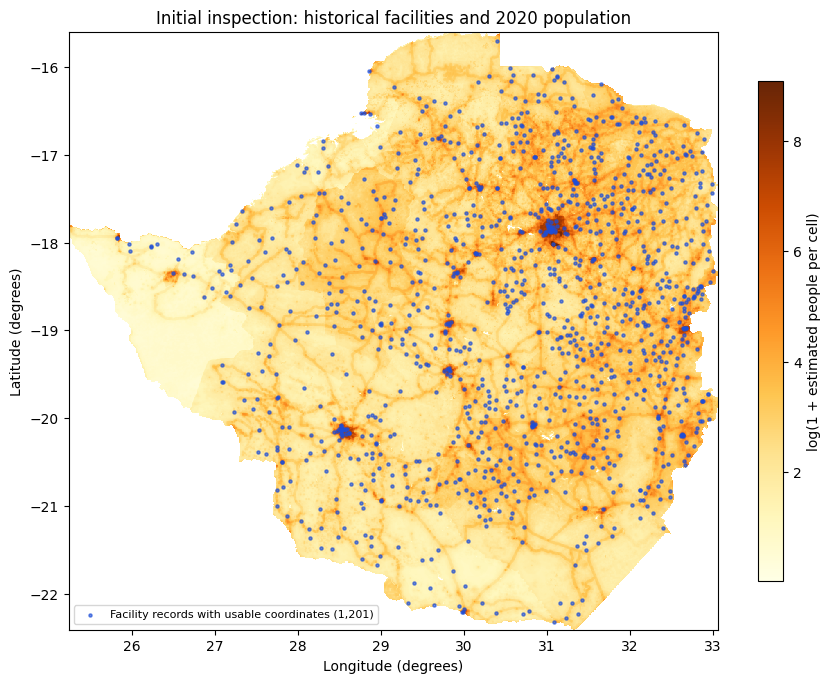

In [7]:
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(np.ma.array(np.log1p(population.filled(0)), mask=np.ma.getmaskarray(population)), extent=raster_extent, origin="upper", cmap="YlOrBr", interpolation="nearest")
ax.scatter(lon[usable_global], lat[usable_global], s=5, color="#1d4ed8", alpha=.65,
           label=f"Facility records with usable coordinates ({usable_global.sum():,})")
ax.set(xlabel="Longitude (degrees)", ylabel="Latitude (degrees)",
       title="Initial inspection: historical facilities and 2020 population")
ax.set_aspect(1 / np.cos(np.deg2rad(-19)))
ax.legend(loc="lower left", fontsize=8)
fig.colorbar(image, ax=ax, shrink=.65, label="log(1 + estimated people per cell)")
plt.tight_layout()
plt.savefig(MAPS / "01_initial_facility_population_map.png", dpi=150, bbox_inches="tight")
plt.show()

### 8. Inspect the supplied boundary layers
The supplied files contain national (ADM0), province (ADM1), district (ADM2) and ward (ADM3) polygons. Administrative units may distinguish urban/rural councils, so the 91 ADM2 features must not be equated automatically with every other definition of Zimbabwe's districts.

Reference line and point layers are included, but they are not district polygons or population locations. We will use polygon layers for containment and reporting units.

Check CRS, geometry types, empty/missing/invalid geometries and unique administrative codes. Basic validity is not a guarantee of gap-free or overlap-free topology. Detailed hierarchy, containment and population assignment checks belong in Notebook 2. No boundary geometry is repaired or altered here.

The source catalogue reports boundaries created in 2018 and reviewed in January 2025. The supplied `valid_on` fields are inspected below. Dates of upload, review and geometry reference are not interchangeable.

In [8]:
import geopandas as gpd
boundary_layers = {}
boundary_audit = []
for name in ["zwe_admin0", "zwe_admin1", "zwe_admin2", "zwe_admin3", "zwe_adminlines", "zwe_adminpoints"]:
    path = RAW / f"{name}.geojson"
    if not path.is_file():
        raise FileNotFoundError(f"Missing boundary layer: {path}. Extract the updated full project package.")
    layer = gpd.read_file(path)
    assert layer.crs is not None, f"Missing CRS: {name}"
    code_column = {"zwe_admin0": "adm0_pcode", "zwe_admin1": "adm1_pcode", "zwe_admin2": "adm2_pcode", "zwe_admin3": "adm3_pcode"}.get(name)
    row = {"layer": name, "features": len(layer), "crs": str(layer.crs),
           "geometry_types": ", ".join(sorted(layer.geom_type.dropna().unique())),
           "missing_geometry": int(layer.geometry.isna().sum()), "empty_geometry": int(layer.is_empty.sum()),
           "invalid_geometry": int((~layer.is_valid & layer.geometry.notna()).sum())}
    if code_column:
        row["missing_codes"] = int(layer[code_column].isna().sum())
        row["duplicate_codes"] = int(layer[code_column].duplicated().sum())
    boundary_audit.append(row)
    boundary_layers[name] = layer
    fingerprints[path.name] = {"bytes": path.stat().st_size, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
boundary_ready = True
print(pd.DataFrame(boundary_audit).to_string(index=False))
print("ADM0 name:", boundary_layers["zwe_admin0"]["adm0_name"].tolist())
print("ADM2 valid_on:", boundary_layers["zwe_admin2"]["valid_on"].astype(str).unique().tolist())
print("Basic layer inspection completed. Detailed topology and spatial assignment checks remain for Notebook 2.")

          layer  features       crs geometry_types  missing_geometry  empty_geometry  invalid_geometry  missing_codes  duplicate_codes
     zwe_admin0         1 EPSG:4326        Polygon                 0               0                 0            0.0              0.0
     zwe_admin1        10 EPSG:4326        Polygon                 0               0                 0            0.0              0.0
     zwe_admin2        91 EPSG:4326        Polygon                 0               0                 0            0.0              0.0
     zwe_admin3      1961 EPSG:4326        Polygon                 0               0                 0            0.0              0.0
 zwe_adminlines      5789 EPSG:4326     LineString                 0               0                 0            NaN              NaN
zwe_adminpoints      2063 EPSG:4326          Point                 0               0                 0            NaN              NaN
ADM0 name: ['Zimbabwe']
ADM2 valid_on: ['2018-09-11']
B

### 9. Save the inspection outputs
Export an unchanged Zimbabwe subset plus inspection flags, aggregate quality checks and source fingerprints. These are provisional review outputs, not final cleaned facility data. The missing-coordinate records remain visible for audit.

No accessibility distances or service-gap claims are produced at this stage.

In [9]:
review = zim.copy()
review["latitude_numeric"] = lat
review["longitude_numeric"] = lon
review["usable_global_coordinates"] = usable_global
review["within_broad_screen"] = broad_screen
review.to_csv(TABLES / "01_zimbabwe_facilities_review.csv", index=False)
for name, series in [("facility_types", types), ("ownership", ownership), ("province_counts", province_counts)]:
    series.rename("records").to_csv(TABLES / f"01_{name}.csv", index_label=name)
quality = {"facility_audit": coordinate_audit, "population_raster": raster_info,
           "boundary_layers_available": boundary_ready, "boundary_audit": boundary_audit,
           "boundary_spatial_validation": "basic inspection complete; topology and containment pending Notebook 2", "versions": versions,
           "source_files": fingerprints,
           "analysis_status": "inspection only; no accessibility metrics calculated"}
(REPORTS / "01_data_quality_report.json").write_text(json.dumps(quality, indent=2), encoding="utf-8")
for path in [FACILITY_PATH, POPULATION_PATH] + list(RAW.glob("zwe_*.geojson")):
    assert hashlib.sha256(path.read_bytes()).hexdigest() == fingerprints[path.name]["sha256"]
pd.DataFrame(boundary_audit).to_csv(TABLES / "01_boundary_layer_audit.csv", index=False)
print("Inspection tables, charts and quality report exported. Raw files unchanged.")
print(f"Findings: {len(zim):,} Zimbabwe records; {usable_global.sum():,} usable coordinate pairs; {missing_pair.sum():,} missing coordinate pairs.")

Inspection tables, charts and quality report exported. Raw files unchanged.
Findings: 1,236 Zimbabwe records; 1,201 usable coordinate pairs; 35 missing coordinate pairs.


### Findings and next step
- The original workbook supports a Zimbabwe country subset and contains facility type and ownership fields.
- Missing coordinates and shared locations need explicit treatment rather than automatic imputation or deletion.
- The 2020 population raster can support a manageable first analysis, with cell-level approximation and mixed reference dates documented.
- Supplied national, province, district and ward boundaries have been inspected for CRS, geometry validity and unique unit codes. Detailed topology, containment and district assignments remain for Notebook 2.

**Next: Notebook 2 — Spatial Cleaning and Preparation.** Resolve coordinate and duplicate issues, inspect the supplied boundary layers, assign facilities to reporting units and prepare population cells while tracking population totals.

### References
Maina, J., et al. (2019). A spatial database of health facilities managed by the public health sector in sub Saharan Africa. *Scientific Data, 6*, 134. https://doi.org/10.1038/s41597-019-0142-2. Data: https://doi.org/10.6084/m9.figshare.7725374.

WorldPop and CIESIN. Global High Resolution Population Denominators Project. Zimbabwe 2020 UN-adjusted 1 km population counts. https://doi.org/10.5258/SOTON/WP00671. Product: https://hub.worldpop.org/geodata/summary?id=38911.

OCHA/HDX. Zimbabwe COD-AB administrative boundaries. https://data.humdata.org/dataset/cod-ab-zwe. Catalogue and user-supplied GeoJSON layers inspected.